**필수 라이브러리 설치**

In [1]:
# 필수 라이브러리 설치 (가장 안정적인 조합)
!pip install opendartreader finance-datareader transformers scikit-learn
!pip install pykrx

# 1. 나눔 폰트 설치
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

!pip install dart-fss
!pip install dart-fss pandas

# 2. 실행 후 반드시 [런타임 다시 시작] 하세요!

INFO: pip is looking at multiple versions of opendartreader to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 4.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.0/65.0 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 30.8 MB/s eta 0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 51 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 0s (29.9 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/

**KoBERT 언어모델 사용**

In [2]:
%%time
# 이 셀을 실행하여 어디서 시간이 걸리는지 체크합니다.

import pandas as pd
import numpy as np
import OpenDartReader
import FinanceDataReader as fdr
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import torch
from transformers import AutoTokenizer, AutoModel

# KoBERT 모델과 토크나이저 로드 (HuggingFace의 skt/kobert-base-v1 활용)
tokenizer = AutoTokenizer.from_pretrained("skt/kobert-base-v1", last_hidden_state=True)
model = AutoModel.from_pretrained("skt/kobert-base-v1")

# GPU 사용 가능 시 설정
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

import time
import re
import numpy as np
import pandas as pd
from datetime import datetime
from bs4 import BeautifulSoup
from pykrx import stock
from sentence_transformers import SentenceTransformer

import time

print("✅ 기본 라이브러리 로드 완료!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/535 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/371k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

KRX 로그인 실패: KRX_ID 또는 KRX_PW 환경 변수가 설정되지 않았습니다.
✅ 기본 라이브러리 로드 완료!
CPU times: user 25.1 s, sys: 3.87 s, total: 28.9 s
Wall time: 50 s


**DART API연결**

In [3]:
# API 키 설정
API_KEY = 'c7044ad42024e5cb43a8ab7fc9d7b7f6ac9bade0'
dart = OpenDartReader(API_KEY)

# 1초 안에 결과가 나와야 정상입니다.
try:
    sample = dart.list('005930', start='2024-01-01').head(1)
    print("🚀 연결 상태 정상: 최근 공시 제목 -", sample['report_nm'].values[0])
except:
    print("❌ 아직 연결에 문제가 있습니다.")

🚀 연결 상태 정상: 최근 공시 제목 - [기재정정]임원ㆍ주요주주특정증권등소유상황보고서


**KOSPI200 리스트 만들기 (csv파일)**

In [ ]:
import FinanceDataReader as fdr

# 코스피 종목 리스트 가져오기
df_kospi = fdr.StockListing('KOSPI')

# 상위 200개 종목 추출 (보통 시가총액 순으로 정렬되어 나옵니다)
# 만약 정렬이 안 되어 있다면: df_kospi = df_kospi.sort_values('MarCap', ascending=False)
kospi_200 = df_kospi.head(200)

# 엑셀에서 보기 편하게 CSV로 저장
kospi_200[['Name', 'Code']].to_csv('kospi200_list.csv', index=False, encoding='utf-8-sig')

**KOSPI200 2014-2025 재무정보 추출**

In [ ]:
import OpenDartReader
import pandas as pd
import sqlite3
import time
from tqdm.auto import tqdm

# 1. 설정
api_key = 'c7044ad42024e5cb43a8ab7fc9d7b7f6ac9bade0'
dart = OpenDartReader(api_key)
csv_filename = 'kospi200_list.csv'
db_name = 'kospi200_merged_final.db'  # 통합 DB 명칭 사용

# 2. 파일 로드
df_tickers = pd.read_csv(csv_filename)
df_tickers['Code'] = df_tickers['Code'].astype(str).str.zfill(6)

# 3. DB 연결 및 테이블 생성 (부채비율 debt_ratio 컬럼 추가)
conn = sqlite3.connect(db_name)
cursor = conn.cursor()
cursor.execute('''
CREATE TABLE IF NOT EXISTS financials_all (
    code TEXT,
    name TEXT,
    year INTEGER,
    revenue REAL,
    op_income REAL,
    net_income REAL,
    assets REAL,
    liabilities REAL,
    equity REAL,
    op_margin REAL,
    roe REAL,
    net_margin REAL,
    debt_ratio REAL,
    PRIMARY KEY (code, year)
)
''')

def get_integrated_data_all_years(code, year):
    try:
        # 단일 연도 전수 수집
        df = dart.finstate_all(code, year)
        if df is None or df.empty: return None

        res = {'rev': 0, 'op': 0, 'ni': 0, 'as': 0, 'li': 0, 'eq': 0}
        mapping = {
            'rev': ['매출액', '영업수익', '수익(매출액)', '이자수익', '보험료수익', '운용수익', '매출', '수익'],
            'op': ['영업이익', '영업이익(손실)', '보험영업이익', '이자이익', '영업손익', '분기영업이익'],
            'ni': ['당기순이익', '당기순이익(손실)', '연결당기순이익', '당기순이익 (손실)', '분기순이익', '총포괄이익'],
            'as': ['자산총계', '자산 총계', '자산', '자산합계'],
            'li': ['부채총계', '부채 총계', '부채', '부채합계'],
            'eq': ['자본총계', '자본 총계', '자본', '자본합계', '지배기업소유주지분']
        }

        for _, row in df.iterrows():
            raw_nm = str(row['account_nm']).replace(" ", "").replace("\n", "")
            try:
                # 데이터가 비어있거나 '0'인 경우 대비
                val = float(row['thstrm_amount']) if pd.notnull(row['thstrm_amount']) else 0
            except: continue

            for key, names in mapping.items():
                if raw_nm in names and res[key] == 0:
                    res[key] = val

        # 데이터 유효성 검사: 매출과 영업이익이 모두 0이면 잘못된 데이터로 간주
        if res['rev'] == 0 and res['op'] == 0: return None

        # 억 단위 절사
        f = {k: round(v / 100000000, 2) for k, v in res.items()}

        # 지표 계산
        op_margin = round((f['op'] / f['rev'] * 100), 2) if f['rev'] != 0 else 0
        roe = round((f['ni'] / f['eq'] * 100), 2) if f['eq'] != 0 else 0
        net_margin = round((f['ni'] / f['rev'] * 100), 2) if f['rev'] != 0 else 0
        debt_ratio = round((f['li'] / f['eq'] * 100), 2) if f['eq'] != 0 else 0

        return [f['rev'], f['op'], f['ni'], f['as'], f['li'], f['eq'], op_margin, roe, net_margin, debt_ratio]
    except:
        return None

# 4. 수집 루프 (2014-2025)
years = range(2014, 2026)
print(f"🚀 KOSPI 200 기업 12개년(2014-2025) 재무 데이터 수집 및 통합 시작...")

for idx, row in df_tickers.iterrows():
    code, name = row['Code'], row['Name']

    for year in years:
        # 이미 데이터가 있는지 확인 (중복 수집 방지)
        cursor.execute("SELECT 1 FROM financials_all WHERE code=? AND year=?", (code, year))
        if cursor.fetchone(): continue

        # 진행 상황 표시
        print(f"[*] {name}({code}) {year}년 데이터 분석 중...", end="\r")

        data = get_integrated_data_all_years(code, year)

        # 유효한 데이터가 수집된 경우에만 DB 저장
        if data:
            # 13개 컬럼 (code, name, year + data 10개)
            cursor.execute('INSERT OR REPLACE INTO financials_all VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)',
                           [code, name, year] + data)
            conn.commit()

        # API 호출 속도 조절 (너무 빠르면 DART에서 차단될 수 있음)
        time.sleep(0.2)

# 5. 성능 최적화 인덱스 생성
cursor.execute("CREATE INDEX IF NOT EXISTS idx_year_code ON financials_all (year, code)")
conn.close()

print("\n✨ 모든 재무 데이터 통합 작업 완료! (2014-2025)")

🚀 200개 기업 10개년 데이터 수집 시작...
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'status': '013', 'message': '조회된 데이타가 없습니다.'}
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
{'status': '013', 'message': '조회된 데이타가 없습니다.'}
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='CFS' (사업보고서, 연결제무제표)'
reprt_code='11011', fs_div='

In [38]:
import pandas as pd
import sqlite3

def export_all_years_to_excel(db_file='kospi200_merged_final.db'):
    # 1. DB 연결 및 전체 데이터 로드
    conn = sqlite3.connect(db_file)
    # 우리가 앞서 통합한 테이블명인 'financials_all'을 사용합니다.
    df = pd.read_sql("SELECT * FROM financials_all", conn)
    conn.close()

    # 2. 분석용 피벗 테이블 생성 (가로: 연도, 세로: 기업명)
    # 2014~2025년까지의 추이를 한눈에 볼 수 있도록 재구성합니다.
    revenue_trend = df.pivot(index='name', columns='year', values='revenue')
    op_income_trend = df.pivot(index='name', columns='year', values='op_income')
    roe_trend = df.pivot(index='name', columns='year', values='roe')
    debt_trend = df.pivot(index='name', columns='year', values='debt_ratio')

    # 3. 엑셀 파일 저장
    file_name = 'KOSPI200_2014_2025_재무분석_통합본.xlsx'

    with pd.ExcelWriter(file_name) as writer:
        # 전체 로우 데이터
        df.to_excel(writer, sheet_name='Raw_Data', index=False)

        # 주요 지표별 시계열 추이
        revenue_trend.to_excel(writer, sheet_name='매출액_추이')
        op_income_trend.to_excel(writer, sheet_name='영업이익_추이')
        roe_trend.to_excel(writer, sheet_name='ROE_추이')
        debt_trend.to_excel(writer, sheet_name='부채비율_추이')

    print(f"✅ 엑셀 파일 저장 완료: {file_name}")
    print(f"📊 포함된 데이터 기간: {df['year'].min()}년 ~ {df['year'].max()}년")

# --- 실행 ---
export_all_years_to_excel()

✅ 엑셀 파일 저장 완료: KOSPI200_2014_2025_재무분석_통합본.xlsx
📊 포함된 데이터 기간: 2015년 ~ 2025년


**🚀 Phase 2: 매크로 유전자 기반 테마 분류 엔진 (2014-2023)이 단계에서는 단순히 업종별(IT, 금융 등)로 기업을 나누는 것이 아니라, 거시경제 지표(금리, 환율, 유가, 금)에 반응하는 기업별 '매크로 유전자'를 추출하여 8개의 동적 테마로 분류합니다.**


1. 분석 목적매크로 민감도 수치화: 각 기업의 주가가 거시경제 변수에 얼마나 민감하게 반응하는지 상관계수로 산출합니다.동적 테마 구축: 고정된 섹터가 아닌, 매년 변화하는 경제 환경 속에서 실제로 같이 움직이는 기업군을 포착합니다.3차 예측 가중치 생성: 향후 AI 주가 예측 모델이 참고할 지표별 중요도(Feature Weight)를 DB화합니다
우리가 사용하는 코드(price.corr(macro_df))는 내부적으로 피어슨 상관계수 공식을 사용합니다.$$r = \frac{\sum (X - \bar{X})(Y - \bar{Y})}{\sqrt{\sum (X - \bar{X})^2 \sum (Y - \bar{Y})^2}}$$

2.   핵심 알고리즘 및 프로세스데이터 정밀화 (Weekly Data): 월간 데이터의 노이즈를 줄이기 위해 주간 수익률 단위로 분석하여 1년당 약 52개의 데이터 포인트를 확보합니다.유전자 추출 (Sensitivity Analysis): 4대 매크로 지표($Interest, FX, Oil, Gold$)와 개별 종목 주가 간의 상관계수를 계산하여 기업별 '민감도 벡터'를 생성합니다.군집화 (K-Means Clustering): 생성된 민감도 벡터를 바탕으로 거시경제 반응 체계가 가장 유사한 기업들을 8개 테마로 묶습니다.표준 가중치 확정 (Intelligence): 각 테마에 속한 기업들의 평균 수치를 계산하여, 해당 테마의 '대표 매크로 유전자'를 확정합니다
3.   **생성되는 결과물 (3차 파이프라인 입력값)company_yearly_sensitivities.csv: 기업별 연도별 매크로 반응도 (Raw Data)theme_yearly_weights.csv: 테마별 표준 가중치 (AI 모델의 직접적 가중치로 활용)company_theme_mapping.csv: 기업별 연도별 테마 소속 기록**


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import FinanceDataReader as fdr
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

# 1. 초기 설정
df_tickers = pd.read_csv('kospi200_list.csv')
df_tickers['Code'] = df_tickers['Code'].astype(str).str.zfill(6)
start_year, end_year = 2014, 2025  # 12개년 전체 확장
macro_factors = ['Interest', 'FX', 'Oil', 'Gold']
n_clusters = 8

# 2. 매크로 데이터 수집 (FRED)
print(f"🌐 FRED 매크로 데이터 수집 중 ({start_year}-{end_year})...")
macro_dict = {
    'Interest': 'REAINTRATREARAT10Y',
    'FX': 'DEXKOUS',
    'Oil': 'POILWTIUSDM',
    'Gold': 'ID7108'
}

macro_data = {}
for f, s in macro_dict.items():
    macro_data[f] = fdr.DataReader(f'FRED:{s}', f'{start_year}-01-01', f'{end_year}-12-31')

macro_df = pd.concat(macro_data, axis=1).ffill().bfill().resample('W').last().pct_change().dropna()
macro_df.columns = macro_factors

# 결과 저장용 바구니
company_sens_data = []
theme_weight_data = []
mapping_df = pd.DataFrame(index=df_tickers['Name'])

# 3. 연도별 통합 루프
print(f"🚀 {start_year}년 ~ {end_year}년 통합 테마 클러스터링 시작...")

for year in range(start_year, end_year + 1):
    y_start, y_end = f"{year}-01-01", f"{year}-12-31"
    m_year = macro_df.loc[y_start:y_end]

    if m_year.empty: continue

    current_year_features = []
    current_year_corps = []

    for _, row in tqdm(df_tickers.iterrows(), total=len(df_tickers), desc=f"Analyzing {year}"):
        try:
            # 주가 데이터 수집
            price = fdr.DataReader(row['Code'], y_start, y_end)['Close'].resample('W').last().pct_change().dropna()
            common_idx = price.index.intersection(m_year.index)

            # 주간 데이터가 충분한 경우에만 상관계수 계산
            if len(common_idx) < 20: continue

            vector = [price.loc[common_idx].corr(m_year.loc[common_idx, f]) for f in macro_factors]
            if any(np.isnan(v) for v in vector): continue

            current_year_features.append(vector)
            current_year_corps.append(row['Name'])
            # [파일명 1 대응] 기업별 민감도 데이터 축적
            company_sens_data.append([year, row['Name']] + vector)
        except: continue

    # 테마 분류 (K-Means)
    if len(current_year_features) >= n_clusters:
        scaled_x = StandardScaler().fit_transform(current_year_features)
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        labels = kmeans.fit_predict(scaled_x)

        # [파일명 2 대응] 기업-테마 매핑
        mapping_df = mapping_df.join(pd.Series(labels, index=current_year_corps, name=f'Theme_{year}'), how='left')

        # [파일명 3 대응] 테마별 평균 DNA 저장
        temp_df = pd.DataFrame(current_year_features, columns=macro_factors)
        temp_df['Theme'] = labels
        theme_avg = temp_df.groupby('Theme').mean()
        for t_id, row_avg in theme_avg.iterrows():
            theme_weight_data.append([year, t_id] + row_avg.tolist())

# 4. 최종 통합 파일 저장
print("\n💾 분석 완료! 통합 결과 파일 생성 중...")

# 1) 기업별 민감도 (사용자 지정 이름)
pd.DataFrame(company_sens_data, columns=['Year', 'Name']+macro_factors).to_csv("company_sensitivities_all_years.csv", index=False, encoding='utf-8-sig')

# 2) 테마별 가중치
pd.DataFrame(theme_weight_data, columns=['Year', 'Theme']+macro_factors).to_csv("theme_weights_all_years.csv", index=False, encoding='utf-8-sig')

# 3) 기업-테마 매핑
mapping_df.fillna('N/A').to_csv("company_theme_mapping_all_years.csv", encoding='utf-8-sig')

print("✅ 모든 통합 파일(_all_years)이 성공적으로 생성되었습니다.")

🌐 매크로 시계열 데이터 수집 중...
🚀 2014년~2023년 10개년 통합 분석 및 테마 추출 시작...


Analyzing 2023: 100%|██████████| 200/200 [03:01<00:00,  1.10it/s]


💾 분석 완료! 결과 파일 생성 중...
✅ 모든 파일이 성공적으로 저장되었습니다.


**연도별 테마분류결과**
N/A는 일정기간 거래정지 혹은 그 년도에 아직 상장이 안된 상태라 테마분류에 포함되지 않음.

In [ ]:
import pandas as pd

# 1. 데이터 로드
weights = pd.read_csv('theme_yearly_weights.csv')
mapping = pd.read_csv('company_theme_mapping.csv')

def generate_full_report():
    report_lines = []
    years = sorted(weights['Year'].unique())

    # 실제 컬럼명 자동 감지
    all_cols = weights.columns.tolist()
    macro_cols = [c for c in all_cols if c in ['Interest', 'FX', 'Oil', 'Gold',
                                              'Interest_W', 'FX_W', 'Oil_W', 'Gold_W']]

    for year in years:
        header = f"\n📅 [{year}년 매크로 테마 분석 결과]"
        print(header)
        report_lines.append(header)
        print("="*100)
        report_lines.append("="*100)

        year_weights = weights[weights['Year'] == year]
        col_name = f'Theme_{year}'

        if col_name not in mapping.columns:
            continue

        for _, row in year_weights.iterrows():
            t_id = int(float(row['Theme']))

            # 해당 테마 소속 종목 추출 (N/A 제외 및 타입 일치)
            members = mapping[mapping[col_name].apply(lambda x: str(x).split('.')[0] == str(t_id))]['Name'].tolist()

            # 매크로 민감도 수치 요약
            sens = row[macro_cols]
            main_factor = sens.abs().astype(float).idxmax()
            main_val = float(sens[main_factor])

            summary = f"테마 #{t_id:^2} | 주요동인: {main_factor:^10} ({main_val:+.3f}) | 종목수: {len(members):>3}개"
            member_list = f"   ㄴ 종목: {', '.join(members)}"

            print(summary)
            print(member_list[:150] + "..." if len(member_list) > 150 else member_list) # 너무 길면 생략해서 출력
            print("-" * 100)

            report_lines.append(summary)
            report_lines.append(member_list)
            report_lines.append("-" * 100)

    # 전체 리스트를 텍스트 파일로 저장
    with open("full_macro_report_2014_2023.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(report_lines))
    print(f"\n✅ 10개년 전체 리스트가 'full_macro_report_2014_2023.txt'로 저장되었습니다.")

# 실행
generate_full_report()


📅 [2014년 매크로 테마 분석 결과]
테마 #0  | 주요동인:    Gold    (+0.284) | 종목수:  11개
   ㄴ 종목: 두산에너빌리티, POSCO홀딩스, HD한국조선해양, 두산, 현대건설, 삼양식품, LG디스플레이, 한온시스템, GS건설, 이마트, 제일기획
----------------------------------------------------------------------------------------------------
테마 #1  | 주요동인:     FX     (+0.161) | 종목수:  21개
   ㄴ 종목: 삼성전기, 삼성생명, 기아, 한화에어로스페이스, LS ELECTRIC, 한국전력, SK텔레콤, 기업은행, KT, 한화솔루션, 금호석유화학, 롯데케미칼, 효성, 한국가스공사, 현대엘리베이터, 현대해상, HD현대마린엔진, 코리안리, 한전KPS, 농심, 코스...
----------------------------------------------------------------------------------------------------
테마 #2  | 주요동인:     FX     (-0.199) | 종목수:  29개
   ㄴ 종목: SK, 셀트리온, LG전자, 미래에셋증권, NAVER, LG이노텍, HMM, 현대글로비스, 한국금융지주, NH투자증권, 삼성증권, DB하이텍, 아모레퍼시픽, 코웨이, 엘앤에프, SKC, CJ, KCC, 롯데쇼핑, 한올바이오파마, CJ제일제당, 코리아써키...
----------------------------------------------------------------------------------------------------
테마 #3  | 주요동인:    Gold    (+0.102) | 종목수:  28개
   ㄴ 종목: SK하이닉스, 현대차, 현대모비스, 삼성SDI, 한화오션, 삼성중공업, 삼성화재, LG화학, LG, 한국항공우주, 대우건설, 한화, 키움증권, 한진

**테마별 상관계수** 2023년도만 보기!

In [ ]:
# 1. 테마별 평균 상관계수 (DNA) 추출
theme_dna = result_df.groupby('Theme').mean()

print(f"📊 2023년 테마별 매크로 유전자(상관계수) 성적표")
print("="*85)
print(f"{'테마번호':^8} | {'금리(Int)':^10} | {'환율(FX)':^10} | {'유가(Oil)':^10} | {'금(Gold)':^10}")
print("-" * 85)

for i in range(len(theme_dna)):
    row = theme_dna.iloc[i]
    print(f"Theme #{i:^5} | {row['Interest']:>10.4f} | {row['FX']:>10.4f} | {row['Oil']:>10.4f} | {row['Gold']:>10.4f}")

print("="*85)
print("💡 수치 해석 가이드:")
print("  - (+): 해당 지표가 오를 때 주가도 같이 오르는 경향 (정상관)")
print("  - (-): 해당 지표가 오를 때 주가는 떨어지는 경향 (역상관)")
print("  - 0에 가까울수록: 해당 매크로 지표의 변화에 무덤덤한 반응")

📊 2023년 테마별 매크로 유전자(상관계수) 성적표
  테마번호   |  금리(Int)   |   환율(FX)   |  유가(Oil)   |  금(Gold)  
-------------------------------------------------------------------------------------
Theme #  0   |    -0.0745 |    -0.0625 |    -0.0127 |     0.0871
Theme #  1   |    -0.0675 |    -0.2290 |     0.1705 |     0.1633
Theme #  2   |     0.1162 |    -0.1569 |     0.1844 |    -0.0767
Theme #  3   |    -0.0158 |    -0.3131 |    -0.0037 |     0.0833
Theme #  4   |     0.0421 |     0.0750 |     0.1193 |     0.0560
Theme #  5   |    -0.2226 |    -0.2252 |     0.0390 |     0.3285
Theme #  6   |    -0.1121 |    -0.3542 |    -0.0975 |     0.1892
Theme #  7   |     0.1917 |    -0.1674 |    -0.1492 |    -0.1637
💡 수치 해석 가이드:
  - (+): 해당 지표가 오를 때 주가도 같이 오르는 경향 (정상관)
  - (-): 해당 지표가 오를 때 주가는 떨어지는 경향 (역상관)
  - 0에 가까울수록: 해당 매크로 지표의 변화에 무덤덤한 반응


**테마별 거시지표 예민성** 시각화 자료 2023년도만

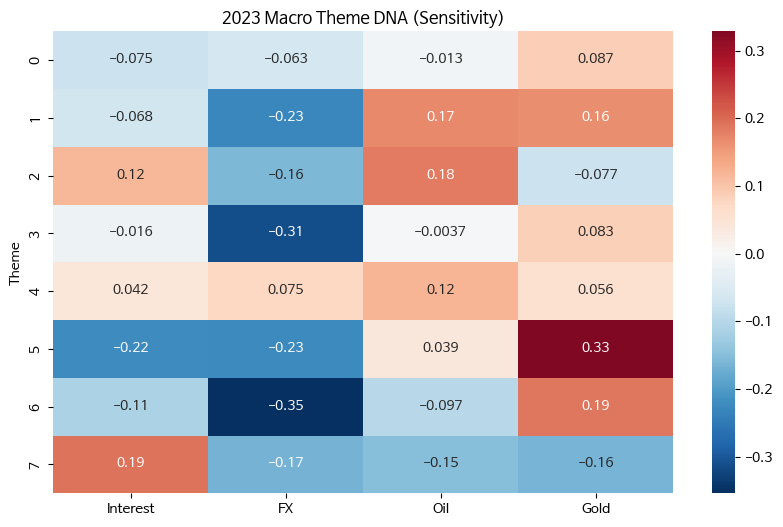

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(theme_dna, annot=True, cmap='RdBu_r', center=0)
plt.title(f"2023 Macro Theme DNA (Sensitivity)")
plt.show()

**KOSPI200 2014-2023년도 종가데이터 수집**

In [ ]:
import FinanceDataReader as fdr
import sqlite3
import pandas as pd
from tqdm.auto import tqdm
import time
import os

def build_db_for_all_years(csv_path='kospi200_list.csv', db_name='kospi200_close_all_years.db'):
    # 1. 종목 리스트 로드
    if not os.path.exists(csv_path):
        print(f"❌ 에러: {csv_path} 파일을 찾을 수 없습니다.")
        return

    df_list = pd.read_csv(csv_path)

    # 컬럼명 대응
    col = 'Code' if 'Code' in df_list.columns else 'code'
    target_codes = df_list[col].astype(str).str.zfill(6).unique().tolist()

    # 2. DB 초기 설정
    conn = sqlite3.connect(db_name)
    cursor = conn.cursor()

    # 기존 테이블 삭제 후 재생성 (Clean Build)
    cursor.execute("DROP TABLE IF EXISTS stock_prices")
    cursor.execute('''
        CREATE TABLE stock_prices (
            Date TEXT,
            Code TEXT,
            Close REAL
        )
    ''')

    print(f"🚀 {len(target_codes)}개 종목 수집 시작 (기간: 2014-01-01 ~ 2025-12-31)")
    print(f"💾 생성 파일명: {db_name}")

    # 3. 데이터 수집 및 저장
    pbar = tqdm(target_codes, desc="주가 데이터 수집 중")

    for code in pbar:
        pbar.set_postfix(current=code)

        try:
            # 12개년치 데이터 호출
            df = fdr.DataReader(code, '2014-01-01', '2025-12-31')

            if not df.empty:
                df = df[['Close']].reset_index()
                df['Code'] = code
                df['Date'] = df['Date'].dt.strftime('%Y-%m-%d')

                # DB 저장 (기존 컬럼 순서 유지)
                df[['Date', 'Code', 'Close']].to_sql('stock_prices', conn, if_exists='append', index=False)

            # API 과부하 방지 (0.1초 대기)
            time.sleep(0.1)

        except Exception as e:
            tqdm.write(f"⚠️ {code} 수집 중 에러 발생: {e}")
            continue

    # 4. 조회 성능 최적화 인덱스 생성
    print("\n⚡ 인덱스(idx_code_date) 생성 중...")
    cursor.execute("CREATE INDEX idx_code_date ON stock_prices (Code, Date)")

    conn.commit()
    conn.close()
    print(f"✅ DB 구축 완료: {db_name}")

# --- 실행 ---
build_db_for_all_years('kospi200_list.csv')

🚀 CSV 리스트 내 200개 종목 수집 시작 (2014-2023)


종가 데이터 수집 중:   0%|          | 0/200 [00:00<?, ?종목/s]


⚡ 최적화 인덱스 생성 중...
✅ DB 구축 완료: kospi200_close_2014_2023.db


**학습용 데이터셋 통합하기**
########## 여기서부터 파일넣고 하시면 됩니다#########

In [7]:
import pandas as pd
import sqlite3
import re
from tqdm.auto import tqdm

# 1. 통합 데이터 로드 (All Years 버전)
print("📂 통합 데이터 로드 시작...")

# CSV 파일들
list_df = pd.read_csv('kospi200_list.csv')
theme_map_df = pd.read_csv('company_theme_mapping_all_years.csv')
theme_weights_df = pd.read_csv('theme_weights_all_years.csv')
sensitivities_df = pd.read_csv('company_sensitivities_all_years.csv')

# DB 파일들
# 재무 DB (최신 업데이트된 financials_all 테이블 사용)
conn_fin = sqlite3.connect('kospi200_merged_final.db')
financials_df = pd.read_sql_query("SELECT * FROM financials_all", conn_fin)
conn_fin.close()

# 주가 DB (통합된 stock_prices 테이블 사용)
conn_price = sqlite3.connect('kospi200_close_all_years.db')
prices_df = pd.read_sql_query("SELECT * FROM stock_prices", conn_price)
conn_price.close()

# --- 데이터 전처리 시작 ---

# [Step 1] 테마 매핑 데이터 변환 (Melt)
# Theme_2014 ~ Theme_2025 컬럼을 행으로 풀기
theme_long = theme_map_df.melt(id_vars=['Name'], var_name='Year', value_name='Theme')
theme_long['Year'] = theme_long['Year'].str.extract(r'(\d+)').astype(int)
# N/A 값 제거 및 타입 통일
theme_long = theme_long[theme_long['Theme'] != 'N/A']
theme_long['Theme'] = pd.to_numeric(theme_long['Theme'], errors='coerce').dropna().astype(int)

# [Step 2] 주가 데이터 전처리 및 종목명 결합
prices_df['Date'] = pd.to_datetime(prices_df['Date'])
prices_df['Year'] = prices_df['Date'].dt.year.astype(int)
prices_df['Code'] = prices_df['Code'].astype(str).str.zfill(6)
list_df['Code'] = list_df['Code'].astype(str).str.zfill(6)

# 종목명(Name) 정보 추가
prices_df = pd.merge(prices_df, list_df[['Code', 'Name']], on='Code', how='left')

# [Step 3] 개별 기업 민감도(Correlation) 결합
sensitivities_df['Year'] = sensitivities_df['Year'].astype(int)
merged_df = pd.merge(prices_df, sensitivities_df, on=['Year', 'Name'], how='left')

# [Step 4] 테마 정보 및 테마 가중치(Weights) 결합
theme_weights_df['Year'] = theme_weights_df['Year'].astype(int)
theme_weights_df['Theme'] = theme_weights_df['Theme'].astype(int)

merged_df = pd.merge(merged_df, theme_long, on=['Year', 'Name'], how='left')
# ⚠️ 중요: 테마별 가중치를 붙여 테마의 성격(DNA)을 데이터에 주입
merged_df = pd.merge(merged_df, theme_weights_df, on=['Year', 'Theme'], how='left', suffixes=('_stock', '_theme'))

# [Step 5] 재무 데이터(Financial DNA) 결합
financials_df.rename(columns={'code': 'Code', 'year': 'Year'}, inplace=True)
financials_df['Year'] = financials_df['Year'].astype(int)
financials_df['Code'] = financials_df['Code'].astype(str).str.zfill(6)

# 재무 데이터 병합 (중복된 name 컬럼은 제외)
merged_df = pd.merge(merged_df, financials_df.drop(columns=['name'], errors='ignore'), on=['Year', 'Code'], how='left')

# --- 최종 데이터 정리 ---
# 결측치 확인 및 정렬
final_dataset = merged_df.sort_values(['Code', 'Date']).reset_index(drop=True)

# 💾 최종 파일 저장
final_dataset.to_csv('kospi200_train_dataset_2014_2025.csv', index=False, encoding='utf-8-sig')

print("\n" + "="*50)
print("✅ 2014-2025 통합 데이터셋 생성이 완료되었습니다!")
print(f"📊 최종 데이터 크기: {final_dataset.shape[0]:,}행 x {final_dataset.shape[1]}열")
print(f"📅 기간: {final_dataset['Year'].min()}년 ~ {final_dataset['Year'].max()}년")
print(f"📁 저장 완료: kospi200_train_dataset_2014_2025.csv")
print("="*50)

✅ 모든 에러가 해결되고 데이터셋 통합이 완료되었습니다!
최종 데이터 크기: (408782, 23)


**XGBoost (Extreme Gradient Boosting)**


Training Strategy: Sliding Window
과거의 데이터가 현재의 시장 질서를 대변하지 못하는 주식 시장의 특성을 반영하여 '슬라이딩 윈도우' 방식을 채택했습니다.

Window Structure: 3-Year Training → 1-Year Prediction

Learning Process: 1.  2014-2016년 데이터를 학습하여 2017년을 예측 및 검증합니다.
2.  윈도우를 1년 뒤로 밀어 2015-2017년 데이터를 학습하고 2018년을 예측합니다.
3.  이 과정을 반복하여 모델이 최신 시장 트렌드(예: 고금리 국면, 팬데믹 등)를 지속적으로 업데이트하도록 설계되었습니다.

🚀 [2014-2025 확장 모델 학습 시작]
-----------------------------------------------------------------
테스트연도    | RMSE     | R2       | 핵심 피처
-----------------------------------------------------------------
2017년 예측 | 0.2182 | -0.2691 | FX_stock
2018년 예측 | 0.1849 | -0.0784 | op_income
2019년 예측 | 0.1808 | -0.1313 | Gold_theme
2020년 예측 | 0.3262 | -0.2167 | debt_ratio
2021년 예측 | 0.2320 | -0.0470 | Interest_theme
2022년 예측 | 0.1745 | -0.1475 | Interest_theme
2023년 예측 | 0.2350 | -0.0219 | FX_theme
2024년 예측 | 0.2329 | 0.0247 | FX_stock
2025년 예측 | 0.3035 | -0.1013 | FX_stock


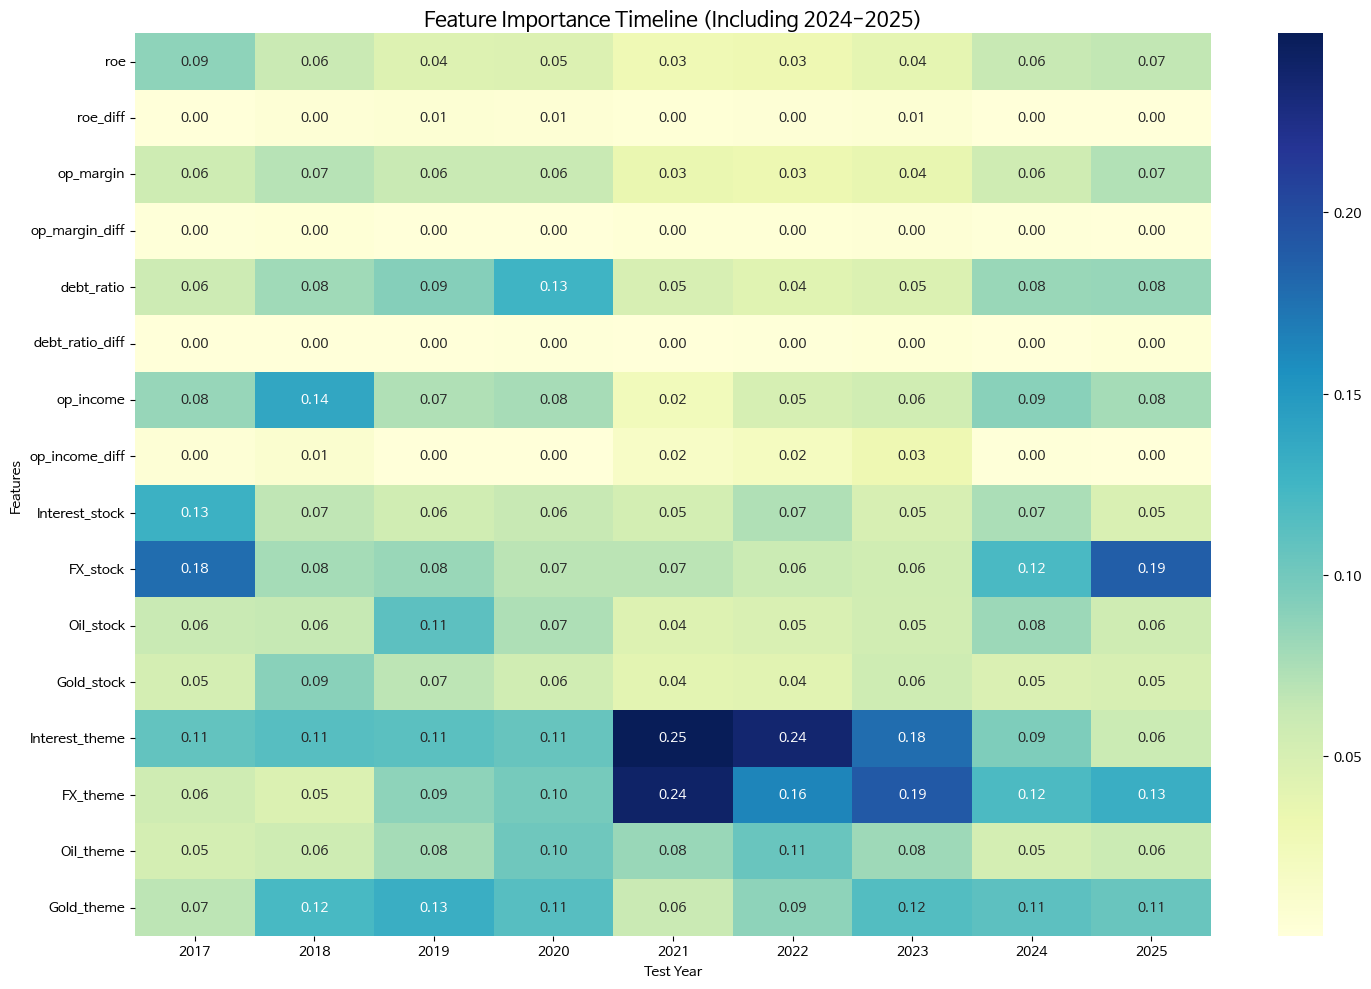

In [28]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# [Step 1] 피처 엔지니어링 보강 (이미 생성된 데이터셋 final_dataset 사용)
df = final_dataset.copy()

# 재무 변화량(Diff) 생성
fin_cols = ['roe', 'op_margin', 'debt_ratio', 'op_income']
for col in fin_cols:
    df[f'{col}_diff'] = df.groupby('Code')[col].diff()

# Target 생성: 60일(약 3개월) 후 수익률
target_days = 60
df['Target_Return'] = df.groupby('Code')['Close'].shift(-target_days) / df['Close'] - 1

# 피처 리스트 (재무수치 + 재무변화량 + 개별민감도 + 테마민감도)
features = [
    'roe', 'roe_diff',
    'op_margin', 'op_margin_diff',
    'debt_ratio', 'debt_ratio_diff',
    'op_income', 'op_income_diff',
    'Interest_stock', 'FX_stock', 'Oil_stock', 'Gold_stock',
    'Interest_theme', 'FX_theme', 'Oil_theme', 'Gold_theme'
]
target = 'Target_Return'

# 학습 가능한 데이터만 필터링 (NaN 제거)
# 2024, 2025 데이터가 포함되었는지 확인이 중요합니다.
train_df = df.dropna(subset=[target] + features).copy()

# [Step 2] 슬라이딩 윈도우 학습 루프 (2025년까지 확장)
importance_history = []
window_years = []
results = []

print(f"🚀 [2014-2025 확장 모델 학습 시작]")
print("-" * 65)
print(f"{'테스트연도':<8} | {'RMSE':<8} | {'R2':<8} | {'핵심 피처'}")
print("-" * 65)

# 2025년까지 예측하기 위해 범위를 조정합니다.
# window_size=3일 때, 2021~23 학습 -> 2024 예측, 2022~24 학습 -> 2025 예측
for start_year in range(2014, 2023):
    window_size = 3
    train_years = list(range(start_year, start_year + window_size))
    test_year = start_year + window_size

    if test_year > 2025: break # 2025년까지만 진행

    X_train = train_df[train_df['Year'].isin(train_years)][features]
    y_train = train_df[train_df['Year'].isin(train_years)][target]
    X_test = train_df[train_df['Year'] == test_year][features]
    y_test = train_df[train_df['Year'] == test_year][target]

    if len(X_test) == 0: continue

    # 모델 설정 (Overfitting 방지를 위한 하이퍼파라미터 조정)
    model = xgb.XGBRegressor(
        n_estimators=200,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method='hist',
        n_jobs=-1,
        random_state=42
    )

    model.fit(X_train, y_train)

    # 예측 및 평가
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    # 중요도 기록
    importances = model.feature_importances_
    top_feature = features[np.argmax(importances)]
    importance_history.append(importances)
    window_years.append(test_year)

    print(f"{test_year}년 예측 | {rmse:.4f} | {r2:.4f} | {top_feature}")

# [Step 3] 피처 중요도 히트맵 시각화
if importance_history:
    plt.figure(figsize=(15, 10))
    importance_df = pd.DataFrame(importance_history, columns=features, index=window_years)
    sns.heatmap(importance_df.T, annot=True, cmap='YlGnBu', fmt='.2f')
    plt.title("Feature Importance Timeline (Including 2024-2025)", fontsize=15)
    plt.ylabel("Features")
    plt.xlabel("Test Year")
    plt.tight_layout()
    plt.show()

In [34]:
# @title 📈 종목별 3개월 뒤 수익률 예측 시뮬레이터 (2014-2025 통합판)

import pandas as pd
import numpy as np
import xgboost as xgb

# [준비] 만약 루프 밖에서 final_model이 정의되지 않았다면 마지막 모델 사용
if 'model' in locals():
    final_model = model
else:
    print("⚠️ 학습된 모델(final_model)을 찾을 수 없습니다. 모델 학습 코드를 먼저 실행해주세요.")

# 1. 사용자로부터 입력 받기
print(f"📊 현재 데이터 가능 범위: 2014년 ~ 2025년")
input_name = input("🔍 예측하고 싶은 종목명을 입력하세요 (예: 삼성전자, LG에너지솔루션): ").strip()
input_year = int(input("📅 분석 기준 연도를 입력하세요 (2014~2025): "))

# 2. 해당 조건의 데이터 추출 (train_df는 이전 단계에서 생성된 데이터프레임)
target_data = train_df[(train_df['Name'] == input_name) & (train_df['Year'] == input_year)].sort_values('Date')

if not target_data.empty:
    # 해당 연도의 데이터 중 가장 최신 시점(또는 첫 시점) 선택
    # 분석 시점을 연초로 잡으려면 head(1), 가장 최근 데이터로 잡으려면 tail(1)
    sample = target_data.tail(1)

    # 3. 모델 추론 (Inference)
    # features 리스트는 이전 모델 학습에서 정의한 리스트 사용
    pred_return = final_model.predict(sample[features])[0]

    # 실제 값 (Target이 존재할 경우에만 유효)
    actual_return = sample[target].values[0] if not pd.isna(sample[target].values[0]) else None

    current_price = sample['Close'].values[0]
    predicted_price = current_price * (1 + pred_return)

    # 4. 결과 대시보드 출력
    print("\n" + "═"*60)
    print(f"🚀 [{input_name}] {input_year}년 분석 시점 데이터 기반 예측")
    print("═"*60)
    print(f"📅 데이터 기준일    : {sample['Date'].dt.date.values[0]}")
    print(f"💰 현재가 (기준일)  : {current_price:,.0f}원")
    print(f"📊 AI 예측 수익률   : {pred_return*100:+.2f}% (3개월 뒤)")
    print(f"🎯 AI 목표 주가     : {predicted_price:,.0f}원")

    if actual_return is not None:
        actual_price = current_price * (1 + actual_return)
        print("-" * 60)
        print(f"✅ 실제 3개월 뒤 수익률: {actual_return*100:+.2f}%")
        print(f"📉 실제 3개월 뒤 주가  : {actual_price:,.0f}원")
        print(f"📌 예측 오차(Error)    : {abs(pred_return - actual_return)*100:.2f}%p")
    else:
        print("-" * 60)
        print(f"⏳ 2025년 하반기 데이터의 경우 실제 결과가 아직 집계되지 않았을 수 있습니다.")
    print("═"*60)

    # 5. 판단 근거 요약 (AI가 중요하게 본 데이터)
    print(f"\n💡 AI의 주요 판단 근거 (Feature Values):")
    cols_to_show = [
        ('재무 개선도(ROE Diff)', 'roe_diff', '+.2f'),
        ('영업이익 변화량', 'op_income_diff', '+,.0f'),
        ('금리 테마 가중치', 'Interest_theme', '.4f'),
        ('유가 종목 민감도', 'Oil_stock', '.4f'),
        ('부채비율 상태', 'debt_ratio', '.2f')
    ]

    for label, col, fmt in cols_to_show:
        if col in sample.columns:
            val = sample[col].values[0]
            print(f"  • {label:<18} : {val:{fmt}}")

else:
    print(f"❌ 데이터를 찾을 수 없습니다. 종목명('{input_name}')과 연도({input_year})를 다시 확인해주세요.")
    print(f"💡 팁: 'Name' 컬럼에 '{input_name}'이 정확히 일치해야 합니다.")

📊 현재 데이터 가능 범위: 2014년 ~ 2025년
🔍 예측하고 싶은 종목명을 입력하세요 (예: 삼성전자, LG에너지솔루션): 셀트리온
📅 분석 기준 연도를 입력하세요 (2014~2025): 2023

════════════════════════════════════════════════════════════
🚀 [셀트리온] 2023년 분석 시점 데이터 기반 예측
════════════════════════════════════════════════════════════
📅 데이터 기준일    : 2023-12-28
💰 현재가 (기준일)  : 185,370원
📊 AI 예측 수익률   : +0.50% (3개월 뒤)
🎯 AI 목표 주가     : 186,295원
------------------------------------------------------------
✅ 실제 3개월 뒤 수익률: -8.78%
📉 실제 3개월 뒤 주가  : 169,087원
📌 예측 오차(Error)    : 9.28%p
════════════════════════════════════════════════════════════

💡 AI의 주요 판단 근거 (Feature Values):
  • 재무 개선도(ROE Diff)   : +0.00
  • 영업이익 변화량           : +0
  • 금리 테마 가중치          : -0.0158
  • 유가 종목 민감도          : -0.0479
  • 부채비율 상태            : 24.80
